In [1]:
%pip install "neo4j>=5.14" pandas numpy scipy scikit-learn networkx matplotlib tqdm

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


# UTS Graf Sains Data — Python Driver Neo4j & Rekomendasi
**Nama:** Salsabila Rinita Candraningtyas  |  **NIM:** 23031554179  
**Dataset:** Roman Zykov (`events.csv`)  
**Fold training (P1):** 29/05/2015 – 29/07/2015  |  **Fold testing (P2):** 07/08/2015 – 22/08/2015

In [ ]:
import os, math, zipfile, warnings
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import networkx as nx
from sklearn.preprocessing import normalize
from tqdm.auto import tqdm
import neo4j
from neo4j import GraphDatabase

warnings.filterwarnings("ignore")

# ====== KONFIGURASI (sesuaikan) ======
URI      = "neo4j://127.0.0.1:7687"
AUTH     = ("neo4j", "utsmantap")      
DB       = "neo4j"
DATA_DIR = "data"
SEED     = 42                          # dipakai di semua proses acak -> reproducible
RESET_DB = False                       
os.makedirs(DATA_DIR, exist_ok=True)

driver = GraphDatabase.driver(URI, auth=AUTH)
driver.verify_connectivity()
print("neo4j driver:", neo4j.__version__)

def q(cypher, **params):
    """Jalankan Cypher, kembalikan list of dict. Kompatibel driver 4.x dan 5.x."""
    with driver.session(database=DB) as s:
        return [r.data() for r in s.run(cypher, **params)]

neo4j driver: 6.4.1


### 1.2 Tutorial driver Neo4j
`execute_query` (driver 5.x) membuka transaksi, menjalankan Cypher, lalu menutupnya sekaligus. Parameter `database_` menentukan
database tujuan dan `routing_=RoutingControl.READ` menandai query baca.

In [ ]:
HAS_EQ = hasattr(driver, "execute_query")

if HAS_EQ:
    from neo4j import RoutingControl

    def add_friend(driver, name, friend_name):
        driver.execute_query(
            "MERGE (a:Person {name: $name}) "
            "MERGE (friend:Person {name: $friend_name}) "
            "MERGE (a)-[:KNOWS]->(friend)",
            name=name, friend_name=friend_name, database_=DB,
        )

    def print_friends(driver, name):
        records, _, _ = driver.execute_query(
            "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
            "RETURN friend.name ORDER BY friend.name",
            name=name, database_=DB, routing_=RoutingControl.READ,
        )
        for record in records:
            print(record["friend.name"])
else:   
    def add_friend(driver, name, friend_name):
        q("MERGE (a:Person {name: $name}) MERGE (friend:Person {name: $friend_name}) "
          "MERGE (a)-[:KNOWS]->(friend)", name=name, friend_name=friend_name)

    def print_friends(driver, name):
        for r in q("MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
                   "RETURN friend.name AS n ORDER BY n", name=name):
            print(r["n"])

with GraphDatabase.driver(URI, auth=AUTH) as drv:
    add_friend(drv, "Arthur", "Guinevere")
    add_friend(drv, "Arthur", "Lancelot")
    add_friend(drv, "Arthur", "Merlin")
    print_friends(drv, "Arthur")

Guinevere
Lancelot
Merlin


**Jawaban Pertanyaan Pendahuluan (Checkpoint)**

1. Nama database yang dipakai adalah neo4j, yaitu database bawaan Neo4j. Namanya ditulis lewat parameter database_="neo4j".
2. Untuk mengakses database lain dalam satu instance, bisa memakai database_="namadb" pada execute_query, atau driver.session(database="namadb"). Lewat Cypher bisa dengan USE namadb. Database lain juga bisa dilihat dan dikelola lewat database system dengan SHOW DATABASES, CREATE DATABASE, dan DROP DATABASE.
3. Graf pertemanan yang dibuat adalah graf berarah (directed) dan tidak berbobot, dengan satu jenis simpul (Person) dan satu jenis relasi (KNOWS). Arthur menjadi simpul asal yang menunjuk ke Guinevere, Lancelot, dan Merlin.

### 1.3 Data RetailRocket
Data yang dipakai adalah events.csv dari dataset Roman Zykov, dengan lima kolom: timestamp (waktu unix dalam milidetik), visitorid (ID pengunjung), event (jenis interaksi: view, addtocart, atau transaction), itemid (ID produk), dan transactionid (ID transaksi, hanya terisi jika event adalah transaction).

In [ ]:
ZIP_PATH   = "ecommerce-dataset.zip"
EVENTS_CSV = os.path.join(DATA_DIR, "events.csv")

if not os.path.exists(EVENTS_CSV) and os.path.exists(ZIP_PATH):
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extract("events.csv", DATA_DIR)

assert os.path.exists(EVENTS_CSV), f"Berkas '{EVENTS_CSV}' tidak ditemukan! Unduh dataset dulu."   

raw_head = pd.read_csv(EVENTS_CSV, nrows=5)
raw_head["datetime_utc"] = pd.to_datetime(raw_head["timestamp"], unit="ms", utc=True)
raw_head

,timestamp,visitorid,event,itemid,transactionid,datetime_utc
0,1433221332117,257597,view,355908,NaN,2015-06-02 05:02:12.117000+00:00
1,1433224214164,992329,view,248676,NaN,2015-06-02 05:50:14.164000+00:00
2,1433221999827,111016,view,318965,NaN,2015-06-02 05:13:19.827000+00:00
3,1433221955914,483717,view,253185,NaN,2015-06-02 05:12:35.914000+00:00
4,1433221337106,951259,view,367447,NaN,2015-06-02 05:02:17.106000+00:00


## 2. Soal UTS
## 2.1 Wrangling dan EDA

### 2.1.1 Penentuan 2 periode waktu
Periode yang digunakan adalah fold training (P1) tanggal 29/05/2015 sampai 29/07/2015 dan fold testing (P2) tanggal 07/08/2015 sampai 22/08/2015. Kolom timestamp pada dataset berupa waktu unix dalam milidetik, jadi kedua tanggal diubah ke milidetik (zona waktu UTC, tanggal akhir ikut dihitung sampai pukul 23:59:59). 

In [ ]:
P1_START, P1_END = "2015-05-29", "2015-07-29"
P2_START, P2_END = "2015-08-07", "2015-08-22"

def to_ms(date_str, end_of_day=False):
    ts = pd.Timestamp(date_str, tz="UTC")
    if end_of_day:                      # batas atas eksklusif 
        ts += pd.Timedelta(days=1)
    return int(ts.value // 1_000_000)   # ns -> ms

WINDOWS = {
    "P1_train": (to_ms(P1_START), to_ms(P1_END, True)),
    "P2_test" : (to_ms(P2_START), to_ms(P2_END, True)),
}
for k, (lo, hi) in WINDOWS.items():
    print(k, pd.to_datetime(lo, unit="ms", utc=True), "->", pd.to_datetime(hi, unit="ms", utc=True), "(eksklusif)")

P1_train 2015-05-29 00:00:00+00:00 -> 2015-07-30 00:00:00+00:00 (eksklusif)
P2_test 2015-08-07 00:00:00+00:00 -> 2015-08-23 00:00:00+00:00 (eksklusif)


### 2.1.2 Filter timestamp dan simpan ke `.csv`
Data P1 (1.320.462 baris) dan P2 (278.993 baris) disaring berdasarkan timestamp lalu disimpan ke events_p1_train.csv dan events_p2_test.csv. Hanya P1 yang dimasukkan ke Neo4j.

In [ ]:
def filter_events(csv_path, windows, chunksize=500_000):
    parts = {name: [] for name in windows}
    for chunk in tqdm(pd.read_csv(csv_path, chunksize=chunksize), desc="Memfilter events.csv"):
        for name, (lo, hi) in windows.items():
            m = (chunk["timestamp"] >= lo) & (chunk["timestamp"] < hi)
            if m.any():
                parts[name].append(chunk[m])
    return {n: pd.concat(v, ignore_index=True) for n, v in parts.items()}

frames = filter_events(EVENTS_CSV, WINDOWS)

OUT = {"P1_train": os.path.join(DATA_DIR, "events_p1_train.csv"),
       "P2_test" : os.path.join(DATA_DIR, "events_p2_test.csv")}
for name, df in frames.items():
    df = df.sort_values("timestamp").reset_index(drop=True)
    df["transactionid"] = df["transactionid"].astype("Int64")          
    df["datetime_utc"]  = pd.to_datetime(df["timestamp"], unit="ms", utc=True)
    df.to_csv(OUT[name], index=False)
    frames[name] = df

summary = pd.DataFrame({
    n: {"baris": len(d), "visitor unik": d.visitorid.nunique(), "item unik": d.itemid.nunique(),
        "view": (d.event=="view").sum(), "addtocart": (d.event=="addtocart").sum(),
        "transaction": (d.event=="transaction").sum(),
        "mulai": d.datetime_utc.min(), "selesai": d.datetime_utc.max()}
    for n, d in frames.items()})
summary

Memfilter events.csv: 0it [00:00, ?it/s]

,P1_train,P2_test
baris,1320462,278993
visitor unik,681797,160627
item unik,170717,78593
view,1277049,269357
addtocart,32596,7362
transaction,10817,2274
mulai,2015-05-29 00:00:00.738000+00:00,2015-08-07 00:00:05.734000+00:00
selesai,2015-07-29 23:59:58.794000+00:00,2015-08-22 23:59:53.877000+00:00


### Impor fold training (P1) ke Neo4j

In [ ]:
REL = {"view": "VIEWED", "addtocart": "ADDED_TO_CART", "transaction": "BOUGHT"}

def create_constraints(session):
    session.run("CREATE CONSTRAINT visitor_id IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE").consume()
    session.run("CREATE CONSTRAINT item_id IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE").consume()

def import_batch(session, event, rows):
    rel   = REL[event]
    props = "{timestamp: row.timestamp, transactionId: row.transactionid}" if event == "transaction" \
            else "{timestamp: row.timestamp}"
    cypher = f"""
    UNWIND $rows AS row
    MERGE (v:Visitor {{visitorId: row.visitorid}})
    MERGE (i:Item {{itemId: row.itemid}})
    CREATE (v)-[:{rel} {props}]->(i)
    """
    session.run(cypher, rows=rows).consume()

def run_import(df, batch_size=20_000):
    with driver.session(database=DB) as session:
        create_constraints(session)
        for start in tqdm(range(0, len(df), batch_size), desc="Mengimpor Batch Data"):
            chunk = df.iloc[start:start + batch_size]
            for event, g in chunk.groupby("event"):
                cols = ["timestamp", "visitorid", "itemid"] + (["transactionid"] if event == "transaction" else [])
                rows = g[cols].astype("int64").to_dict("records")
                import_batch(session, event, rows)

if RESET_DB:   # hanya menghapus Visitor/Item, per 10.000 simpul agar tidak memori tidak habis
    with driver.session(database=DB) as s:
        s.run("MATCH (n) WHERE n:Visitor OR n:Item CALL { WITH n DETACH DELETE n } IN TRANSACTIONS OF 10000 ROWS").consume()

existing = q("MATCH (:Visitor)-[r]->(:Item) RETURN count(r) AS c")[0]["c"]
if existing == 0:
    run_import(frames["P1_train"])
    print("Proses impor berhasil.")
else:
    print(f"Graf sudah berisi {existing:,} relasi Visitor->Item; impor dilewati (set RESET_DB=True bila ingin mengulang).")

Received notification from DBMS server: <GqlStatusObject gql_status='01N50', status_description='warn: label does not exist. The label `Visitor` does not exist in database `neo4j`. Verify that the spelling is correct.', position=<SummaryInputPosition line=1, column=9, offset=8>, raw_classification='UNRECOGNIZED', classification=<NotificationClassification.UNRECOGNIZED: 'UNRECOGNIZED'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'UNRECOGNIZED', '_severity': 'WARNING', '_position': {'offset': 8, 'line': 1, 'column': 9}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: 'MATCH (:Visitor)-[r]->(:Item) RETURN count(r) AS c'
Received notification from DBMS server: <GqlStatusObject gql_status='01N50', status_description='warn: label does not exist. The label `Item` does not exist in database `neo4j`. Verify that the spelling is correct.', position=<SummaryInputPosition line=1, column=25, offset=24>

Mengimpor Batch Data:   0%|          | 0/67 [00:00<?, ?it/s]

Proses impor berhasil.


### 2.1.3 Komposisi subgraph (jenis simpul dan jumlahnya)
Subgraph yang terbentuk terdiri dari simpul Visitor sebanyak [681797] dan simpul Item sebanyak [170717]. Relasinya ada tiga jenis, yaitu VIEWED sebanyak [1277049], ADDED_TO_CART sebanyak [32596], dan BOUGHT sebanyak [10817].

In [8]:
nodes = pd.DataFrame(q("""
    MATCH (n) WHERE n:Visitor OR n:Item
    RETURN labels(n)[0] AS jenis_simpul, count(*) AS jumlah
    ORDER BY jumlah DESC"""))
rels = pd.DataFrame(q("""
    MATCH (:Visitor)-[r]->(:Item)
    RETURN type(r) AS jenis_relasi, count(*) AS jumlah
    ORDER BY jumlah DESC"""))
display(nodes); display(rels)

# validasi silang terhadap CSV P1
p1 = frames["P1_train"]
print("CSV  -> visitor unik:", p1.visitorid.nunique(), "| item unik:", p1.itemid.nunique(), "| baris:", len(p1))
print("Neo4j-> total relasi :", int(rels.jumlah.sum()))

,jenis_simpul,jumlah
0,Visitor,681797
1,Item,170717


,jenis_relasi,jumlah
0,VIEWED,1277049
1,ADDED_TO_CART,32596
2,BOUGHT,10817


CSV  -> visitor unik: 681797 | item unik: 170717 | baris: 1320462
Neo4j-> total relasi : 1320462


### 2.1.4 – 2.1.5 Vector Space Modelling (VSM)
Graf Visitor-Item diubah menjadi matriks interaksi X. Baris mewakili visitor (user), kolom mewakili item, dan isi sel adalah bobot interaksi: view = 1, addtocart = 3, transaction = 5. Bobot ini saya tentukan sendiri, dengan alasan makin kuat sinyal minatnya, makin besar nilainya. Data diambil dari graf Neo4j dengan menjumlahkan bobot untuk setiap pasangan visitor-item, lalu disimpan dalam format sparse karena sebagian besar selnya kosong.

In [9]:
W = {"VIEWED": 1.0, "ADDED_TO_CART": 3.0, "BOUGHT": 5.0}

rows = q("""
    MATCH (v:Visitor)-[r]->(i:Item)
    RETURN v.visitorId AS u, i.itemId AS i, type(r) AS t, count(*) AS c""")

def build_matrix(rows, W):
    df = pd.DataFrame(rows)
    df["w"] = df["t"].map(W) * df["c"]
    ui = df.groupby(["u", "i"], as_index=False)["w"].sum()
    user_ids, u_idx = np.unique(ui["u"].values, return_inverse=True)
    item_ids, i_idx = np.unique(ui["i"].values, return_inverse=True)
    X = sp.csr_matrix((ui["w"].values, (u_idx, i_idx)), shape=(len(user_ids), len(item_ids)))
    return X, user_ids, item_ids

X, user_ids, item_ids = build_matrix(rows, W)     # User x Item
Xt = X.T.tocsr()                                   # Item x User
print("X  (User x Item):", X.shape, "| nnz =", X.nnz)
print("Xt (Item x User):", Xt.shape)

X  (User x Item): (681797, 170717) | nnz = 1028054
Xt (Item x User): (170717, 681797)


In [11]:
def describe_matrix(M, nama, baris, kolom):
    M = M.tocsr()
    nnz_per_row = np.diff(M.indptr)
    n_r, n_c = M.shape
    return {
        "vektor": baris, "dimensi vektor (ruang)": f"{n_c:,} ({kolom})", "shape": f"{n_r:,} x {n_c:,}",
        "nnz (sel terisi)": f"{M.nnz:,}", "density": f"{M.nnz/(n_r*n_c):.6%}", "sparsity": f"{1-M.nnz/(n_r*n_c):.4%}",
        "rata2 nnz/vektor": round(nnz_per_row.mean(), 2), "median nnz/vektor": float(np.median(nnz_per_row)),
        "max nnz/vektor": int(nnz_per_row.max()),
        "% vektor dgn 1 entri": f"{(nnz_per_row==1).mean():.2%}",
        "memori sparse (MB)": round((M.data.nbytes + M.indices.nbytes + M.indptr.nbytes)/1e6, 1),
        "memori jika dense (GB)": round(n_r*n_c*8/1e9, 1),
    }

def plot_degree_hist(M, judul, xlabel):
    d = np.diff(M.tocsr().indptr)
    plt.figure(figsize=(6, 3.5))
    plt.hist(d, bins=np.logspace(0, np.log10(max(d.max(), 10)), 40), color="#4c78a8")
    plt.xscale("log"); plt.yscale("log"); plt.xlabel(xlabel); plt.ylabel("frekuensi"); plt.title(judul)
    plt.tight_layout(); plt.show()

def plot_bipartite_sample(X, n_users=12, items_per_user=3):
    """Cuplikan graf bipartit: user paling aktif + item berbobot tertinggi miliknya."""
    deg = np.diff(X.indptr)
    G = nx.Graph()
    for u in np.argsort(-deg)[:n_users]:
        row = X[u]
        for it in row.indices[np.argsort(-row.data)[:items_per_user]]:
            G.add_edge(f"U{user_ids[u]}", f"I{item_ids[it]}")
    colors = ["#e45756" if n.startswith("U") else "#4c78a8" for n in G]
    plt.figure(figsize=(8, 6))
    nx.draw_networkx(G, nx.spring_layout(G, seed=SEED), node_color=colors, node_size=120, width=0.7, with_labels=False)
    plt.axis("off")
    plt.title("Cuplikan graf bipartit (merah = User, biru = Item)"); plt.show()

def plot_projection_sample(M, n=40, min_sim=0.0, judul=""):
    """Proyeksi cosine pada n vektor terpadat; simpul = baris M, sisi = cosine > min_sim."""
    M = M.tocsr()
    top = np.argsort(-np.diff(M.indptr))[:n]
    sub = normalize(M[top])
    S = (sub @ sub.T).toarray(); np.fill_diagonal(S, 0)
    G = nx.Graph(); G.add_nodes_from(range(len(top)))
    for a, b in zip(*np.where(np.triu(S) > min_sim)):
        G.add_edge(int(a), int(b), weight=float(S[a, b]))
    pos = nx.spring_layout(G, seed=SEED, weight="weight")
    w = [G[a][b]["weight"] * 3 for a, b in G.edges]
    plt.figure(figsize=(7, 6))
    nx.draw_networkx(G, pos, node_size=140, node_color="#72b7b2", width=w, edge_color="#999", with_labels=False)
    plt.title(f"{judul} | {G.number_of_nodes()} simpul, {G.number_of_edges()} sisi"); plt.axis("off"); plt.show()
    return G

### 2.1.4 VSM terhadap simpul User

,VSM User
vektor,User/Visitor
dimensi vektor (ruang),"170,717 (item)"
shape,"681,797 x 170,717"
nnz (sel terisi),"1,028,054"
density,0.000883%
sparsity,99.9991%
rata2 nnz/vektor,1.51
median nnz/vektor,1.0
max nnz/vektor,2404
% vektor dgn 1 entri,80.29%


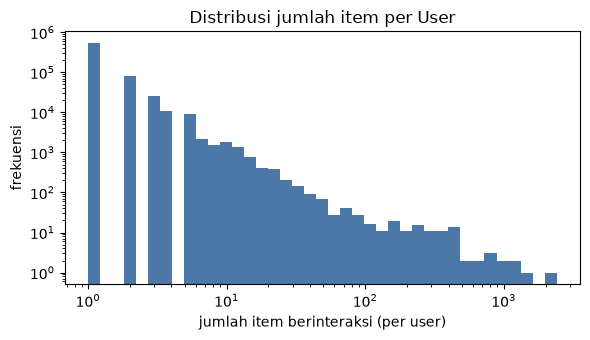

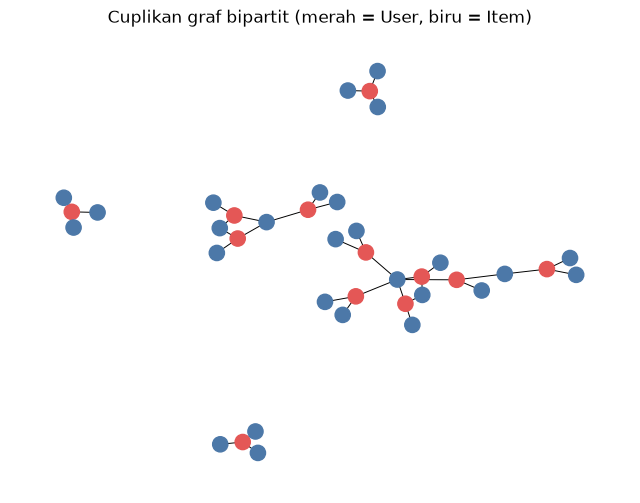

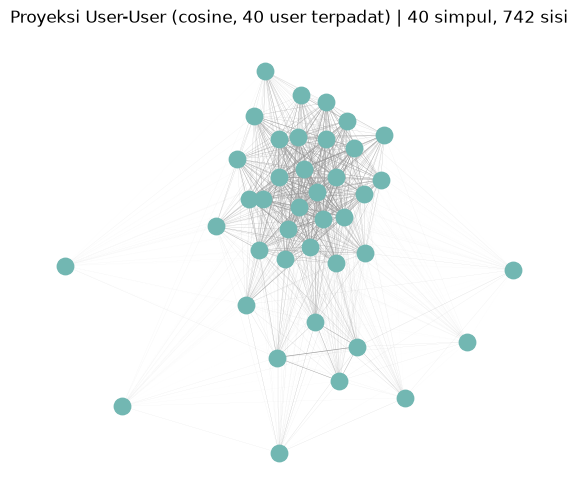

In [12]:
user_stats = describe_matrix(X, "User", "User/Visitor", "item")
display(pd.Series(user_stats, name="VSM User").to_frame())
plot_degree_hist(X, "Distribusi jumlah item per User", "jumlah item berinteraksi (per user)")
plot_bipartite_sample(X)
G_user = plot_projection_sample(X, n=40, judul="Proyeksi User-User (cosine, 40 user terpadat)")

Pada VSM ini setiap user (visitor) menjadi satu vektor, dan dimensinya adalah jumlah item, yaitu 170.717. Matriks interaksinya berukuran 681.797 × 170.717, artinya ada 681.797 user dan 170.717 item. Hanya 1.028.054 sel yang terisi, sehingga kepadatannya cuma 0,000883% dan sparsity-nya 99,9991%. Nilai sel adalah bobot interaksi: view 1, addtocart 3, dan transaction 5.

Rata-rata satu user hanya berinteraksi dengan 1,51 item, dan mediannya 1. Sebanyak 80,29% user hanya punya satu item. Di sisi lain ada user yang sangat aktif, dengan interaksi sampai 2.404 item. Jadi sebaran datanya sangat timpang: kebanyakan user hanya menyentuh satu item, sedikit user menyentuh sangat banyak item.

Matriks ini hanya bisa disimpan karena memakai format sparse, yaitu sekitar 15,1 MB. Kalau disimpan penuh (dense), ukurannya sekitar 931,2 GB, jauh melebihi kapasitas memori komputer biasa.

Pada plot networkx, [isi sesuai gambar, misalnya: user-user yang terhubung karena membuka item yang sama mengumpul di sekitar user yang paling aktif, sedangkan user lain terhubung lebih jarang]. Karena sebagian besar user hanya punya satu item, kemiripan cosine antar-user banyak yang bernilai 0 atau sangat besar tanpa banyak informasi, sehingga vektor user kurang cocok dipakai untuk mengukur kemiripan.

### 2.1.5 VSM terhadap simpul Item

,VSM Item
vektor,Item
dimensi vektor (ruang),"681,797 (user)"
shape,"170,717 x 681,797"
nnz (sel terisi),"1,028,054"
density,0.000883%
sparsity,99.9991%
rata2 nnz/vektor,6.02
median nnz/vektor,2.0
max nnz/vektor,1617
% vektor dgn 1 entri,40.42%


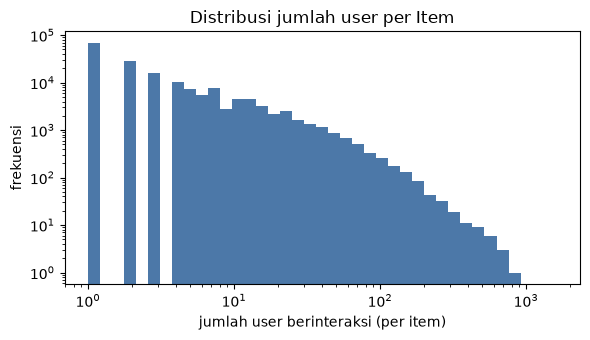

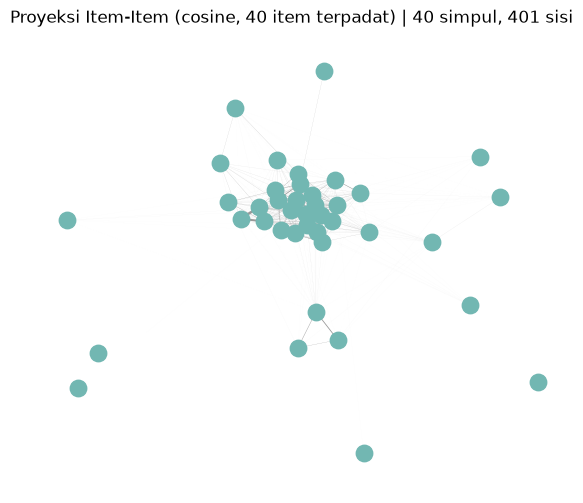

In [13]:
item_stats = describe_matrix(Xt, "Item", "Item", "user")
display(pd.Series(item_stats, name="VSM Item").to_frame())
plot_degree_hist(Xt, "Distribusi jumlah user per Item", "jumlah user berinteraksi (per item)")
G_item = plot_projection_sample(Xt, n=40, judul="Proyeksi Item-Item (cosine, 40 item terpadat)")

Pada VSM ini setiap item menjadi satu vektor, dan dimensinya adalah jumlah user, yaitu 681.797. Matriksnya berukuran 170.717 × 681.797. Ini adalah transpos dari matriks user-item sebelumnya, jadi jumlah sel terisi (1.028.054), kepadatan (0,000883%), dan sparsity (99,9991%) sama persis. Yang berbeda adalah sudut pandangnya: sekarang yang dibaca adalah baris per item.

Rata-rata satu item dilihat atau dibeli oleh 6,02 user, dengan median 2. Item yang paling ramai disentuh oleh 1.617 user. Sebanyak 40,42% item hanya punya satu user. Angka ini jauh lebih kecil dibanding vektor user, yang 80,29% hanya punya satu item. Artinya vektor item lebih banyak isinya, meskipun distribusinya tetap timpang: banyak item yang jarang disentuh dan sedikit item yang sangat populer.

Ukuran matriks sparse-nya sekitar 13,0 MB, sedangkan jika disimpan penuh (dense) mencapai 931,2 GB, sehingga tetap harus memakai format sparse.

Pada plot networkx, [isi sesuai gambar, misalnya: item-item populer menjadi pusat yang terhubung ke banyak item lain, karena sering dibuka oleh user yang sama]. Karena satu item rata-rata disentuh lebih banyak user, perbandingan cosine antar-item lebih bermakna daripada antar-user.

### 2.1.6 Proyeksi mana yang lebih baik (efektif / efisien)?
Perbandingan dilakukan dengan angka, bukan asumsi:

- **Efisiensi:** ukuran matriks kesamaan (`n×n` dense) dan **batas atas jumlah sisi proyeksi** = banyaknya pasangan simpul yang berbagi minimal satu tetangga,
  yaitu `Σ C(derajat, 2)` — untuk proyeksi User dihitung dari derajat tiap Item, untuk proyeksi Item dari derajat tiap User.
- **Efektivitas:** seberapa besar entitas di P2 (testing) yang **sudah dikenal** di P1 (training). Kesamaan hanya bisa dipakai pada entitas yang punya vektor di training.

In [ ]:
d_item_per_user = np.diff(X.indptr).astype(np.int64)        
d_user_per_item = np.diff(Xt.indptr).astype(np.int64)       
edges_user_proj = int((d_user_per_item * (d_user_per_item - 1) // 2).sum())   
edges_item_proj = int((d_item_per_user * (d_item_per_user - 1) // 2).sum())   

p2 = frames["P2_test"]
cover_user = p2["visitorid"].drop_duplicates().isin(user_ids).mean()
cover_item = p2["itemid"].drop_duplicates().isin(item_ids).mean()

cmp = pd.DataFrame({
    "Proyeksi User-User": {"jumlah simpul": len(user_ids), "matriks dense (GB)": round(len(user_ids)**2*8/1e9, 1),
                           "batas atas sisi": edges_user_proj, "rata2 tetangga langsung per vektor asal": round(d_item_per_user.mean(), 2),
                           "% entitas P2 yang dikenal di P1": f"{cover_user:.2%}"},
    "Proyeksi Item-Item": {"jumlah simpul": len(item_ids), "matriks dense (GB)": round(len(item_ids)**2*8/1e9, 1),
                           "batas atas sisi": edges_item_proj, "rata2 tetangga langsung per vektor asal": round(d_user_per_item.mean(), 2),
                           "% entitas P2 yang dikenal di P1": f"{cover_item:.2%}"},
})
display(cmp)

lebih_efisien  = "Item-Item" if edges_item_proj < edges_user_proj else "User-User"
lebih_efektif  = "Item-Item" if cover_item > cover_user else "User-User"
print("Lebih efisien :", lebih_efisien)
print("Lebih efektif :", lebih_efektif)

,Proyeksi User-User,Proyeksi Item-Item
jumlah simpul,681797,170717
matriks dense (GB),3718.8,233.2
batas atas sisi,23150019,13118421
rata2 tetangga langsung per vektor asal,1.51,6.02
% entitas P2 yang dikenal di P1,6.21%,78.84%


Lebih efisien : Item-Item
Lebih efektif : Item-Item


**Menurut saya proyeksi Item-Item lebih baik, baik dari sisi efisiensi maupun efektivitas.**

Efisiensi. Jumlah simpul pada proyeksi Item-Item hanya 170.717, sedangkan User-User 681.797 (sekitar 4 kali lebih banyak). Jika matriks kemiripannya disimpan penuh, Item-Item membutuhkan sekitar 233,2 GB dan User-User sekitar 3.718,8 GB, jadi User-User kira-kira 16 kali lebih besar. Perkiraan batas atas jumlah sisi (pasangan simpul yang punya tetangga bersama) juga lebih kecil untuk Item-Item, yaitu 13.118.421 dibanding 23.150.019 untuk User-User, atau sekitar 43% lebih sedikit. Selisih sisinya tidak sebesar selisih ukuran matriks, tetapi arahnya tetap sama, yaitu Item-Item lebih ringan dihitung.

Efektivitas. Perbedaan terbesar ada di sini. Sebanyak 78,84% item yang muncul di P2 (testing) sudah pernah muncul di P1 (training), sedangkan untuk user hanya 6,21%. Artinya sebagian besar visitor di P2 adalah pengunjung baru yang tidak punya vektor di data training, sehingga kemiripan antar-user hampir tidak bisa dipakai untuk memprediksi perilaku mereka. Item, sebaliknya, sebagian besar sudah punya riwayat sehingga kemiripannya masih bisa dimanfaatkan.

Vektor item juga lebih padat. Rata-rata satu item disentuh 6,02 user, sedangkan satu user rata-rata hanya menyentuh 1,51 item. Dengan isi yang lebih banyak, nilai cosine antar-item lebih bermakna dibanding antar-user.

Karena itu perhitungan similarity (2.1.7) dan rekomendasi KNN (2.2) memakai proyeksi Item-Item.

### 2.1.7 Similarity pada graf terproyeksi (Item–Item, cosine)
Similarity dihitung dengan cosine similarity antar vektor item pada proyeksi Item-Item, yaitu hasil kali dua vektor dibagi hasil kali panjangnya. Nilainya antara 0 sampai 1. Semakin besar nilainya, semakin sering dua item dilihat atau dibeli oleh user yang sama.

Record acuan yang saya pilih adalah item 5411, karena item ini paling banyak berinteraksi dengan user di P1, yaitu 1.617 user. Lima item yang paling mirip dengannya, dari yang tertinggi, adalah item 33030 dengan cosine 0,1645, item 256242 dengan cosine 0,1275, item 33956 dengan cosine 0,1079, item 37807 dengan cosine 0,1018, dan item 89143 dengan cosine 0,0986.

Nilai cosine-nya tidak besar (paling tinggi 0,1645). Ini wajar karena datanya sangat sparse, dan item 5411 dilihat oleh banyak user yang berbeda-beda, sehingga hanya sebagian kecil dari mereka yang juga membuka item lain yang sama. Meski kecil, urutannya tetap menunjukkan item mana yang paling dekat dengan item acuan.

In [15]:
Xn  = normalize(Xt)            # Item x User, baris dinormalisasi L2
XnT = Xn.T.tocsr()             # User x Item

def item_neighbors(rows_idx, k, exclude=None):
    """k tetangga cosine terdekat untuk tiap baris item. exclude = indeks item yang tidak boleh jadi tetangga.
    Tie-break deterministik (nilai desc, indeks asc). Hasil: list[(indeks_item, sim)] per item."""
    exclude = np.array(sorted(exclude), dtype=np.int64) if exclude else np.array([], dtype=np.int64)
    S = (Xn[rows_idx] @ XnT).tocsr()
    out = []
    for r, pos in enumerate(rows_idx):
        sl = slice(S.indptr[r], S.indptr[r + 1])
        cols, vals = S.indices[sl], S.data[sl]
        keep = cols != pos
        if exclude.size:
            keep &= ~np.isin(cols, exclude)
        cols, vals = cols[keep], vals[keep]
        order = np.lexsort((cols, -vals))[:k]
        out.append(list(zip(cols[order].tolist(), vals[order].tolist())))
    return out

ref_pos = int(np.argmax(np.diff(Xt.indptr)))
ref_id  = int(item_ids[ref_pos])
top5    = item_neighbors([ref_pos], k=5)[0]
sim_df  = pd.DataFrame({"item_acuan": ref_id, "item_mirip": [int(item_ids[c]) for c, _ in top5],
                        "cosine": [round(s, 4) for _, s in top5]})
print(f"Item acuan: {ref_id} (jumlah user = {int(np.diff(Xt.indptr)[ref_pos])})")
sim_df

Item acuan: 5411 (jumlah user = 1617)


,item_acuan,item_mirip,cosine
0,5411,33030,0.1645
1,5411,256242,0.1275
2,5411,33956,0.1079
3,5411,37807,0.1018
4,5411,89143,0.0986


**7b. Menulis similarity ke graf.**
Kelima pasangan di atas ditulis ke graf sebagai relasi SIMILAR_TO dari item acuan ke item mirip, dengan properti score yang berisi nilai cosine. Saya memakai MERGE supaya relasi tidak dobel kalau sel dijalankan ulang, dan SET s.score = ... untuk menyimpan nilainya. 

In [16]:
WRITE_SIM = """
UNWIND $rows AS r
MATCH (a:Item {itemId: r.src}), (b:Item {itemId: r.dst})
MERGE (a)-[s:SIMILAR_TO]->(b)
SET s.score = r.score, s.method = 'cosine_item_item', s.weights = 'view1_cart3_buy5', s.fold = 'P1'
RETURN count(s) AS relasi_ditulis
"""
rows_w = [{"src": ref_id, "dst": int(i), "score": float(s)} for i, s in zip(sim_df.item_mirip, sim_df.cosine)]
print(q(WRITE_SIM, rows=rows_w))

[{'relasi_ditulis': 5}]


In [17]:
TOP5_CYPHER = """
MATCH (a:Item {itemId: $ref})-[s:SIMILAR_TO]->(b:Item)
RETURN a.itemId AS item_acuan, b.itemId AS item_mirip, s.score AS cosine
ORDER BY s.score DESC
LIMIT 5
"""
print(TOP5_CYPHER)
pd.DataFrame(q(TOP5_CYPHER, ref=ref_id))


MATCH (a:Item {itemId: $ref})-[s:SIMILAR_TO]->(b:Item)
RETURN a.itemId AS item_acuan, b.itemId AS item_mirip, s.score AS cosine
ORDER BY s.score DESC
LIMIT 5



,item_acuan,item_mirip,cosine
0,5411,33030,0.1645
1,5411,256242,0.1275
2,5411,33956,0.1079
3,5411,37807,0.1018
4,5411,89143,0.0986


**7a. Cypher untuk 5 record dengan similarity tertinggi**:
MATCH mencari item acuan beserta item-item yang terhubung lewat relasi SIMILAR_TO. ORDER BY s.score DESC mengurutkan dari nilai terbesar, dan LIMIT 5 mengambil lima teratas. Hasilnya sama persis dengan tabel di atas, sehingga nilai yang tersimpan di graf sudah sesuai dengan hasil perhitungan di Python.

### 2.1.8 Kondisi graf sebelum dan sesudah perhitungan similarity
Pada gambar menampilkan item acuan 5411 (merah), lima item termirip (biru), dan sebagian visitor yang pernah berinteraksi dengan item acuan sekaligus salah satu dari lima item tersebut (abu-abu). Untuk menjaga gambar tetap terbaca, hanya 30 pasangan visitor-item yang ditampilkan.

Sebelum similarity. Graf hanya berisi relasi antara visitor dan item. Item 5411 tidak terhubung langsung ke item 33030, 256242, 33956, 37807, dan 89143. Keterkaitan mereka hanya bisa dilihat secara tidak langsung, yaitu lewat visitor yang sama-sama membuka item acuan dan salah satu item lainnya. Pada gambar, item 33030 punya paling banyak visitor bersama dengan item 5411, sedangkan item 89143 dan 256242 hanya punya sedikit.

Sesudah similarity. Relasi visitor-item tetap sama, tetapi ditambah lima relasi baru SIMILAR_TO (panah merah putus-putus) dari item 5411 ke masing-masing item mirip. Setiap relasi membawa nilai cosine sebagai score, yaitu 0,165 untuk item 33030, 0,128 untuk item 256242, 0,108 untuk item 33956, 0,102 untuk item 37807, dan 0,099 untuk item 89143. Urutan nilainya sesuai dengan banyaknya visitor bersama pada gambar, karena item 33030 yang paling banyak berbagi visitor memang mendapat nilai tertinggi.

Dengan relasi baru ini, kemiripan antar-item bisa dibaca langsung dari satu relasi tanpa harus menelusuri visitor satu per satu.

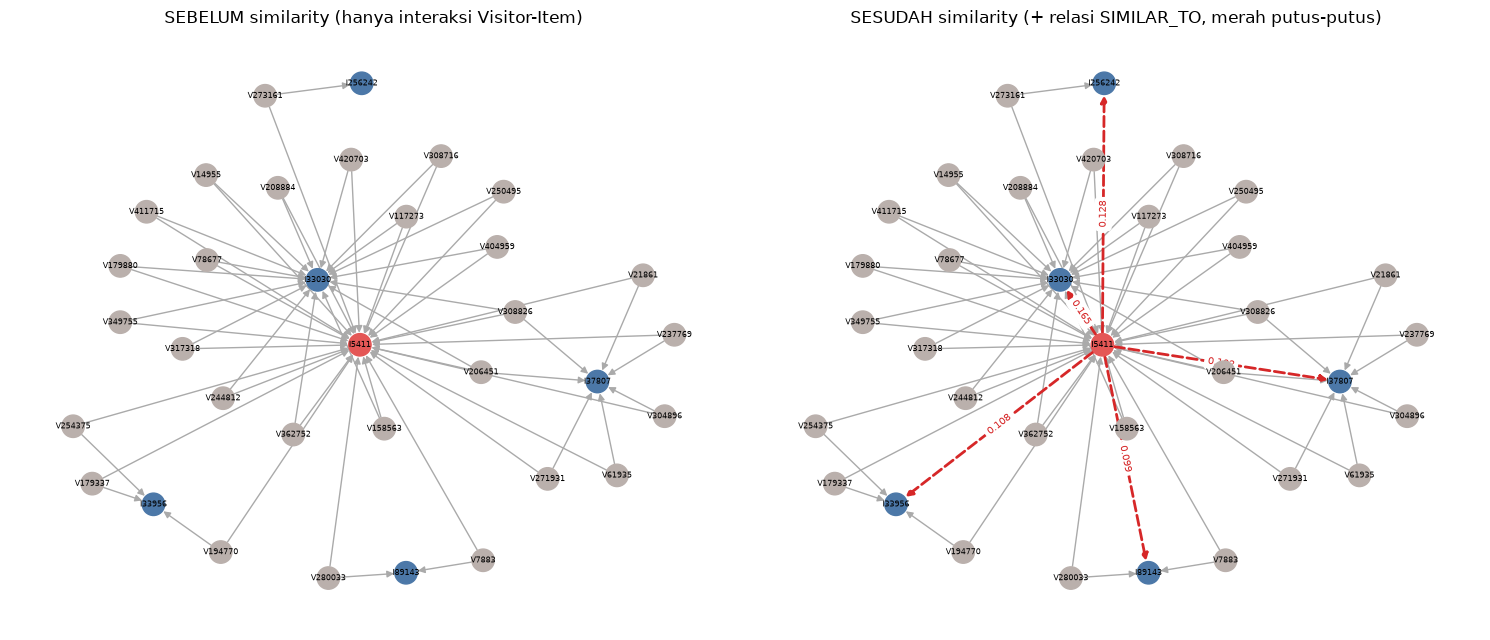

In [18]:
nbr_ids = [int(item_ids[c]) for c, _ in top5]

BEFORE = """
MATCH (ref:Item {itemId: $ref})<-[r1]-(v:Visitor)-[r2]->(j:Item)
WHERE j.itemId IN $nbrs
RETURN DISTINCT v.visitorId AS visitor, j.itemId AS item
ORDER BY visitor, item LIMIT 30
"""
AFTER = """
MATCH (ref:Item {itemId: $ref})-[s:SIMILAR_TO]->(j:Item)
RETURN ref.itemId AS src, j.itemId AS dst, s.score AS score
"""
rows_before = q(BEFORE, ref=ref_id, nbrs=nbr_ids)
rows_sim    = q(AFTER, ref=ref_id)

def build_graph(with_sim):
    G = nx.DiGraph()
    G.add_node(f"I{ref_id}", kind="ref")
    for r in rows_before:
        v, j = f"V{r['visitor']}", f"I{r['item']}"
        G.add_node(v, kind="visitor"); G.add_node(j, kind="item")
        G.add_edge(v, f"I{ref_id}", rel="interaksi"); G.add_edge(v, j, rel="interaksi")
    if with_sim:
        for r in rows_sim:
            G.add_node(f"I{r['dst']}", kind="item")
            G.add_edge(f"I{ref_id}", f"I{r['dst']}", rel="SIMILAR_TO", score=r["score"])
    return G

def draw(G, ax, judul, pos):
    col = {"ref": "#e45756", "item": "#4c78a8", "visitor": "#bab0ac"}
    nx.draw_networkx_nodes(G, pos, node_color=[col[G.nodes[n]["kind"]] for n in G], node_size=260, ax=ax)
    nx.draw_networkx_labels(G, pos, font_size=6, ax=ax)
    base = [e for e in G.edges if G.edges[e]["rel"] == "interaksi"]
    sims = [e for e in G.edges if G.edges[e]["rel"] == "SIMILAR_TO"]
    nx.draw_networkx_edges(G, pos, edgelist=base, edge_color="#aaaaaa", arrows=True, ax=ax)
    if sims:
        nx.draw_networkx_edges(G, pos, edgelist=sims, edge_color="#d62728", style="dashed", width=2, ax=ax)
        nx.draw_networkx_edge_labels(G, pos, {e: f"{G.edges[e]['score']:.3f}" for e in sims}, font_size=7, font_color="#d62728", ax=ax)
    ax.set_title(judul); ax.axis("off")

G_after  = build_graph(True)
pos = nx.spring_layout(G_after.to_undirected(), seed=SEED)
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
draw(build_graph(False), axes[0], "SEBELUM similarity (hanya interaksi Visitor-Item)", pos)
draw(G_after,            axes[1], "SESUDAH similarity (+ relasi SIMILAR_TO, merah putus-putus)", pos)
plt.tight_layout(); plt.show()

## 2.2 Analytics
### 2.2.1 Pemilihan user acak (reproducible) dan rekomendasi KNN
User dipilih dari 3.474 user yang layak uji (minimal 2 item di P1 dan membuka minimal satu item baru di P2) menggunakan numpy.random.default_rng(42) pada daftar ID yang sudah diurutkan, sehingga hasilnya selalu sama saat dijalankan ulang. User yang terpilih adalah 131452, dengan 10 item di P1 dan dua item baru di P2 (kunci jawaban), yaitu 203759 dan 358664.

Metode yang dipakai adalah KNN berbasis item dengan k = 5. Untuk setiap item yang pernah dibuka user, diambil 5 item termirip (cosine) yang belum pernah ia buka. Skor kandidat adalah jumlah dari bobot item milik user dikali nilai cosine, lalu kandidat diurutkan dari skor terbesar.

Lima rekomendasi teratas adalah item 85488 (skor 0,5000), 452375 (0,2500), 264908 (0,2041), 245526 (0,1021), dan 49126 (0,0877).

Tiga item yang diiklankan untuk user 131452 adalah 85488, 452375, dan 264908.

In [19]:
def user_items(pos):
    r = slice(X.indptr[pos], X.indptr[pos + 1])
    return X.indices[r], X.data[r]

def recommend_item_knn(u_pos, k=5, topn=5):
    seen_idx, w = user_items(u_pos)
    seen = set(seen_idx.tolist())
    scores = {}
    for j, wj, nbrs in zip(seen_idx, w, item_neighbors(seen_idx.tolist(), k, exclude=seen)):
        for c, s in nbrs:
            scores[c] = scores.get(c, 0.0) + wj * s
    ranked = sorted(scores.items(), key=lambda t: (-t[1], t[0]))[:topn]
    return [(int(item_ids[c]), float(s)) for c, s in ranked]

Un  = normalize(X)
UnT = Un.T.tocsr()
def recommend_user_knn(u_pos, k=5, topn=5):
    S = (Un[u_pos] @ UnT).tocsr()
    cols, vals = S.indices, S.data
    keep = cols != u_pos
    cols, vals = cols[keep], vals[keep]
    order = np.lexsort((cols, -vals))[:k]
    nb, sims = cols[order], vals[order]
    if len(nb) == 0:
        return []
    agg = (sp.csr_matrix(sims.reshape(1, -1)) @ X[nb]).toarray().ravel()
    agg[user_items(u_pos)[0]] = 0
    cand = np.where(agg > 0)[0]
    cand = cand[np.lexsort((cand, -agg[cand]))][:topn]
    return [(int(item_ids[c]), float(agg[c])) for c in cand]

def popularity_rec(u_pos, topn=5):
    seen = set(user_items(u_pos)[0].tolist())
    return [int(item_ids[c]) for c in POP_ORDER if c not in seen][:topn]
POP_ORDER = np.argsort(-np.asarray(Xt.sum(axis=1)).ravel(), kind="stable")

def hit_at_k(recs, gt, k=5):
    return int(any(r in gt for r in recs[:k]))

def ndcg_at_k(recs, gt, k=5):
    dcg  = sum(1.0 / math.log2(i + 2) for i, r in enumerate(recs[:k]) if r in gt)
    idcg = sum(1.0 / math.log2(i + 2) for i in range(min(len(gt), k)))
    return dcg / idcg if idcg > 0 else 0.0

In [20]:
# ground truth per user dari P2: item P2 yang BARU bagi user dan ada di katalog P1
item_set = set(item_ids.tolist())
p2_sets = p2.groupby("visitorid")["itemid"].apply(set).to_dict()
user_pos_of = pd.Series(np.arange(len(user_ids)), index=user_ids)

def ground_truth(uid):
    pos = user_pos_of[uid]
    seen = set(item_ids[user_items(pos)[0]].tolist())
    return {i for i in p2_sets.get(uid, set()) if i not in seen and i in item_set}

eligible = []
for uid in sorted(set(user_ids.tolist()) & set(p2_sets)):
    if len(user_items(user_pos_of[uid])[0]) >= 2 and ground_truth(uid):
        eligible.append(uid)
print("User layak uji:", len(eligible))

rng = np.random.default_rng(SEED)
target_id  = int(rng.choice(np.array(eligible)))
target_pos = int(user_pos_of[target_id])
gt         = ground_truth(target_id)
print("User terpilih (seed =", SEED, "):", target_id)
print("Jumlah item training user:", len(user_items(target_pos)[0]), "| item kunci jawaban (P2):", sorted(gt))

User layak uji: 3474
User terpilih (seed = 42 ): 131452
Jumlah item training user: 10 | item kunci jawaban (P2): [203759, 358664]


### 2.2.1(a) Skrip rekomendasi KNN (k = 5) dan 2.2.1(b) 3 item yang diiklankan

In [21]:
K = 5
recs = recommend_item_knn(target_pos, k=K, topn=5)
rec_ids = [i for i, _ in recs]

print(f"Top-5 kandidat (item-based KNN, k={K}):")
display(pd.DataFrame(recs, columns=["itemid", "skor"]).assign(peringkat=lambda d: d.index + 1)[["peringkat", "itemid", "skor"]])
print("==> 3 item yang DIIKLANKAN untuk user", target_id, ":", rec_ids[:3])

Top-5 kandidat (item-based KNN, k=5):


,peringkat,itemid,skor
0,1,85488,0.500000
1,2,452375,0.250000
2,3,264908,0.204124
3,4,245526,0.102062
4,5,49126,0.087706


==> 3 item yang DIIKLANKAN untuk user 131452 : [85488, 452375, 264908]


### 2.2.2 Hit@5 dan NDCG@5
Kunci jawaban untuk user 131452 adalah item 203759 dan 358664, yaitu item yang ia buka di P2 tetapi belum pernah ia buka di P1. Lima rekomendasi (85488, 452375, 264908, 245526, dan 49126) tidak ada yang cocok dengan keduanya.

Hit@5 bernilai 1 jika minimal satu dari 5 rekomendasi ada di kunci jawaban, dan 0 jika tidak. Hasilnya Hit@5 = 0.
NDCG@5 memperhitungkan urutan: item benar di peringkat atas mendapat nilai lebih besar, dengan DCG = jumlah dari 1/log₂(peringkat+1) untuk item yang benar. DCG ini dibagi IDCG, yaitu DCG jika item benar berada di peringkat teratas. Karena tidak ada item yang benar, DCG = 0, sehingga NDCG@5 = 0.

In [22]:
hit  = hit_at_k(rec_ids, gt, 5)
ndcg = ndcg_at_k(rec_ids, gt, 5)
print(f"User {target_id}")
print("Item benar (hit) di top-5:", [i for i in rec_ids[:5] if i in gt])
print(f"Hit@5  = {hit}")
print(f"NDCG@5 = {ndcg:.4f}")

User 131452
Item benar (hit) di top-5: []
Hit@5  = 0
NDCG@5 = 0.0000
